# 01 — Keşif ve Temizleme

Bu notebook'ta veriyi tanıyoruz: Neler var, ne kadar temiz, şarkılar ve türler ilk bakışta nasıl görünüyor?

**Veri:** [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) — 114 tür × 1.000 şarkı.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))  # src/ klasörünü import edebilmek için
from src.veri import SES_OZELLIKLERI, temizle, tekil_sarkilar, veri_yukle

FIGURLER = Path.cwd().parent / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Veriye ilk bakış

In [2]:
ham = veri_yukle()
print(ham.shape)
ham.head()

(114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


**Sütunların anlamı (Spotify'ın tanımlarıyla, çoğu 0–1 arası):**

| Sütun | Anlamı |
|---|---|
| `popularity` | 0–100 popülerlik puanı (son dönemdeki dinlenme sayısına göre) |
| `danceability` | Dans etmeye ne kadar uygun |
| `energy` | Yoğunluk ve hareketlilik |
| `loudness` | Ortalama ses yüksekliği (dB, negatif değerler) |
| `speechiness` | Konuşma oranı (podcast/rap yüksek) |
| `acousticness` | Akustik olma olasılığı |
| `instrumentalness` | Sözsüz olma olasılığı |
| `liveness` | Canlı kayıt olma olasılığı |
| `valence` | Müzikal "mutluluk" (1 = neşeli, 0 = hüzünlü/gergin) |
| `tempo` | Dakikadaki vuruş sayısı (BPM) |

In [3]:
ham.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

## 2. Veri kalitesi

### 2.1 Eksik değerler

In [4]:
eksik = ham.isna().sum()
eksik[eksik > 0]

artists       1
album_name    1
track_name    1
dtype: int64

In [5]:
ham[ham["track_name"].isna()]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


Sadece 1 satırda isim bilgileri eksik. Bu satırı atmak analizi etkilemez.

### 2.2 Tekrar eden kayıtlar

In [6]:
print("Tamamen aynı satır sayısı:", ham.duplicated().sum())
print("Birden fazla kez geçen track_id sayısı:", ham["track_id"].duplicated().sum())

Tamamen aynı satır sayısı: 450
Birden fazla kez geçen track_id sayısı: 24259


İki farklı tekrar türü var:

1. **Tamamen aynı satırlar:** Gerçek kopyalar, atılmalı.
2. **Aynı `track_id` farklı satırlarda:** Bir şarkı birden fazla türün listesinde yer alıyor. Örneğin bir şarkı hem `pop` hem `dance` olabilir.

Bir şarkının kaç farklı türde geçtiğine bakalım:

In [7]:
tur_sayisi = ham.groupby("track_id")["track_genre"].nunique()
tur_sayisi.value_counts().sort_index().head(10)

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [8]:
# En çok türde geçen şarkılar
en_cok = tur_sayisi.sort_values(ascending=False).head(5).index
(ham[ham["track_id"].isin(en_cok)]
 .groupby(["track_name", "artists"])["track_genre"]
 .apply(lambda s: ", ".join(sorted(s.unique()))))

track_name                     artists             
Baby Blue - Remastered 2010    Badfinger               blues, country, folk, j-pop, j-rock, power-pop...
Keep My Name Outta Your Mouth  The Black Keys          alt-rock, alternative, blues, garage, punk, pu...
Layla                          Derek & The Dominos     blues, british, country, folk, hard-rock, psyc...
Midnight Rider                 Allman Brothers Band    blues, country, folk, hard-rock, j-rock, singe...
Name: track_genre, dtype: str

**Karar:** Tür analizlerinde bu satırları koruyoruz, çünkü her biri farklı bir türü temsil ediyor. Şarkı düzeyindeki analizlerde (popülerlik tahmini, benzer şarkı bulucu) her şarkıdan yalnızca birini kullanacağız (`tekil_sarkilar`). Aksi hâlde aynı şarkı hem eğitim hem test verisine düşer ve model olduğundan başarılı görünür.

### 2.3 Anlamsız değerler

In [9]:
print("Süresi 0 ms:", (ham["duration_ms"] == 0).sum())
print("Tempo 0:", (ham["tempo"] == 0).sum())
print("Ölçü (time_signature) 0:", (ham["time_signature"] == 0).sum())

Süresi 0 ms: 1
Tempo 0: 157
Ölçü (time_signature) 0: 163


In [10]:
ham[ham["tempo"] == 0][["track_name", "artists", "track_genre", "duration_ms", "speechiness"]].head(8)

,track_name,artists,track_genre,duration_ms,speechiness
4131,The Departure,Max Richter;Lang Lang,ambient,151506,0.0
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,ambient,73266,0.0
4664,Ferme Les Yeux,Sylvain Chauveau,ambient,68493,0.0
45670,Campomoro,Little Symphony,guitar,148711,0.0
45720,Ritornello,Little Symphony,guitar,102000,0.0
45729,Amager,Little Symphony,guitar,133624,0.0
45773,Ionian,Little Symphony,guitar,93125,0.0
59221,Yes! No! I Mean Yes! No I Don't!,Leila Bela,iranian,38333,0.0


Tempo ya da ölçü bilgisi 0 olan kayıtlar çoğunlukla ambient, klasik ve solo gitar gibi belirgin bir vuruşu olmayan parçalar. Spotify bunlarda ritmi ölçememiş. Sayıları az (~160) ve tempo değerleri yanıltıcı olduğu için bu satırları atıyoruz.

### 2.4 Temizleme

In [11]:
df = temizle(ham)
sarkilar = tekil_sarkilar(df)

print(f"Ham veri:              {len(ham):>7,} satır")
print(f"Temiz (tür düzeyi):    {len(df):>7,} satır")
print(f"Tekil şarkı:           {len(sarkilar):>7,} şarkı")

Ham veri:              114,000 satır
Temiz (tür düzeyi):    113,386 satır
Tekil şarkı:            89,578 şarkı


## 3. Ses özelliklerinin dağılımı

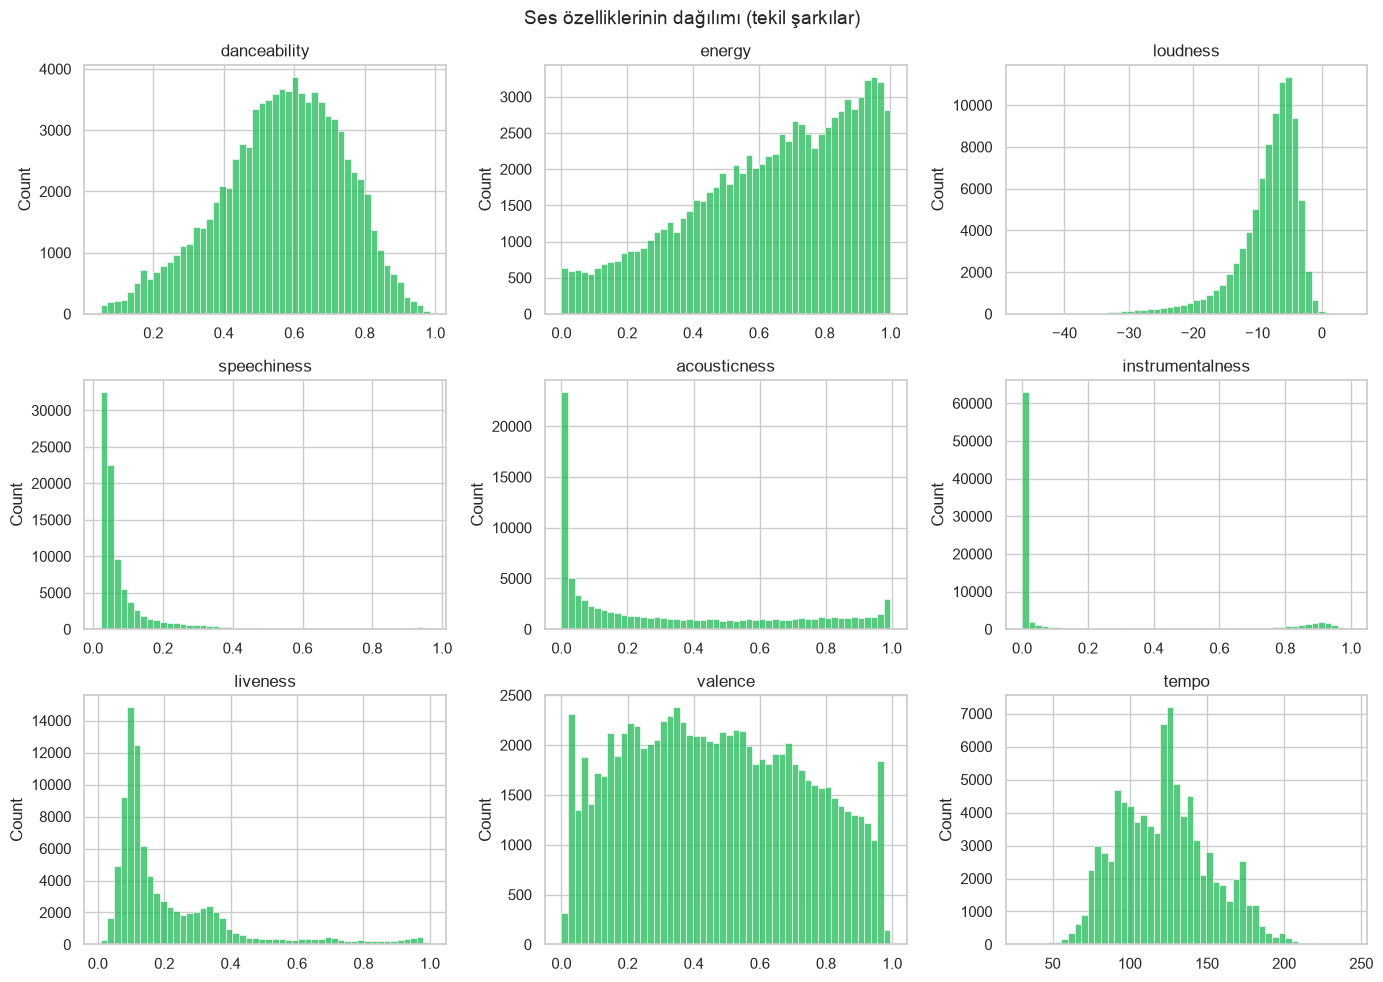

In [12]:
fig, eksenler = plt.subplots(3, 3, figsize=(14, 10))
for eksen, ozellik in zip(eksenler.flat, SES_OZELLIKLERI):
    sns.histplot(sarkilar[ozellik], bins=50, ax=eksen, color="#1DB954")
    eksen.set_title(ozellik)
    eksen.set_xlabel("")
fig.suptitle("Ses özelliklerinin dağılımı (tekil şarkılar)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURLER / "01_dagilimlar.png", dpi=120)
plt.show()

**Gözlemler:**
- `danceability` çan eğrisine benziyor, ortası 0.6 civarında.
- `valence` (mutluluk) neredeyse düz dağılıyor. Veri setinde hüzünlü ve neşeli şarkılar dengeli temsil ediliyor.
- `energy` yükseğe kaymış. Şarkıların çoğu enerjik.
- `instrumentalness` iki gruba ayrılıyor: büyük çoğunluk 0'da (sözlü şarkılar), küçük bir grup 0.9 civarında (sözsüz parçalar). Bu ayrım kümelemede işimize yarayacak.
- `speechiness` ve `liveness` sıfıra yakın yığılmış. Şarkıların çoğu konuşma içermiyor ve stüdyo kaydı.
- `acousticness` çoğunlukla 0'a yakın, 1'de ise küçük ikinci bir tepe var (tamamen akustik parçalar).

## 4. Popülerlik

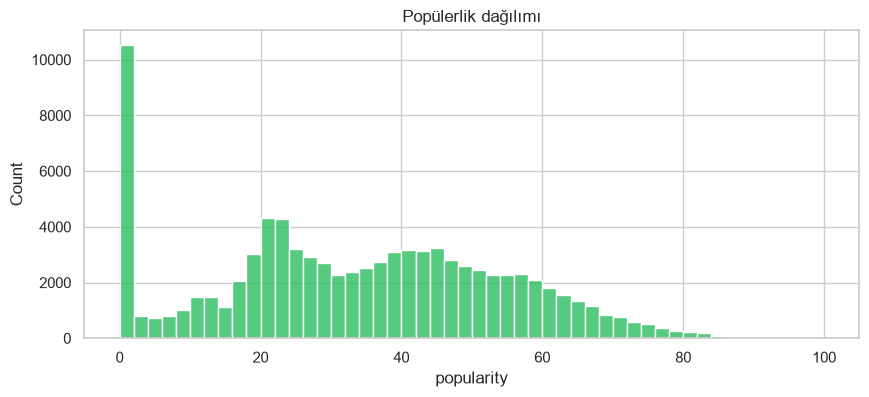

Popülerliği 0 olan şarkı oranı: 10.5%


In [13]:
fig, eksen = plt.subplots(figsize=(10, 4))
sns.histplot(sarkilar["popularity"], bins=50, ax=eksen, color="#1DB954")
eksen.set_title("Popülerlik dağılımı")
plt.show()

print("Popülerliği 0 olan şarkı oranı:", f"{(sarkilar['popularity'] == 0).mean():.1%}")

Popülerliği tam 0 olan şarkılar dikkat çekiyor. Bunlar ya hiç dinlenmeyen ya da Spotify'ın başka bir sürümünü öne çıkardığı şarkılar olabilir. Popülerlik tahmini notebook'unda bu konuya döneceğiz.

## 5. Özellikler arası ilişki

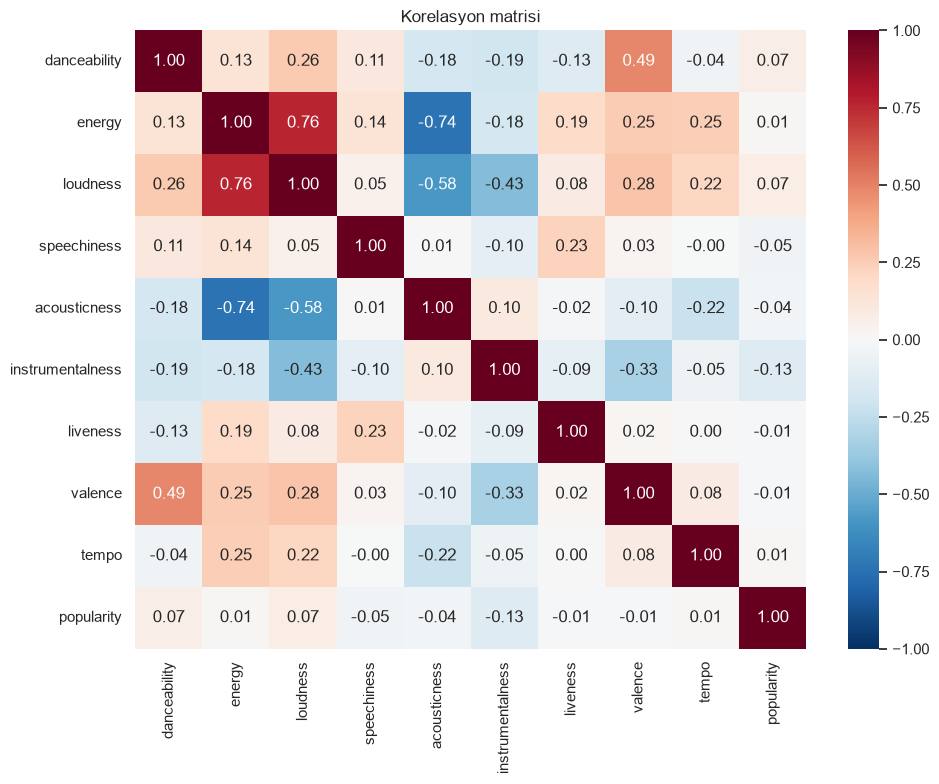

In [14]:
korelasyon = sarkilar[SES_OZELLIKLERI + ["popularity"]].corr()

fig, eksen = plt.subplots(figsize=(10, 8))
sns.heatmap(korelasyon, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=eksen)
eksen.set_title("Korelasyon matrisi")
fig.tight_layout()
fig.savefig(FIGURLER / "01_korelasyon.png", dpi=120)
plt.show()

In [15]:
# Popülerlikle en güçlü ilişkiler
korelasyon["popularity"].drop("popularity").sort_values(key=abs, ascending=False)

instrumentalness   -0.128502
loudness            0.073237
danceability        0.065950
speechiness        -0.046864
acousticness       -0.038969
energy              0.014426
liveness           -0.014277
valence            -0.010951
tempo               0.008781
Name: popularity, dtype: float64

## 6. Türler: Kim en mutlu, kim en enerjik?

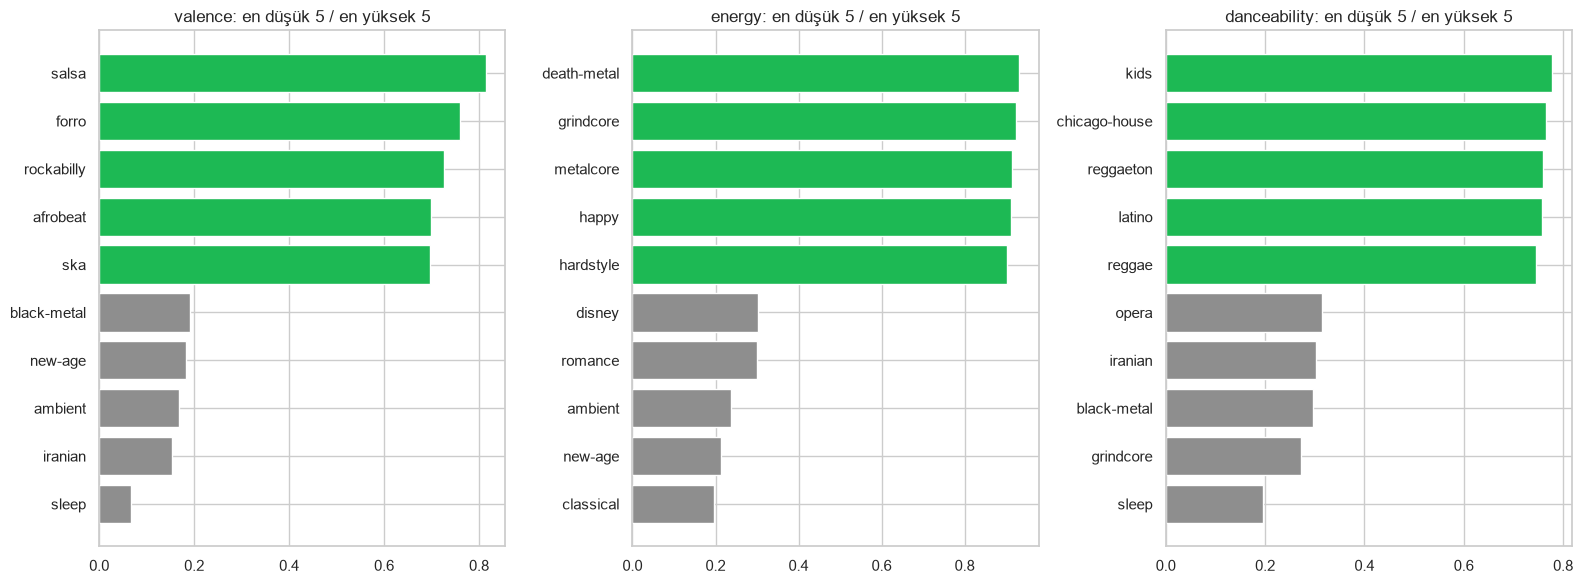

In [16]:
tur_ort = df.groupby("track_genre")[SES_OZELLIKLERI + ["popularity"]].mean()

fig, eksenler = plt.subplots(1, 3, figsize=(16, 6))
for eksen, ozellik in zip(eksenler, ["valence", "energy", "danceability"]):
    sirali = tur_ort[ozellik].sort_values()
    secim = pd.concat([sirali.head(5), sirali.tail(5)])
    renkler = ["#8E8E8E"] * 5 + ["#1DB954"] * 5
    eksen.barh(secim.index, secim.values, color=renkler)
    eksen.set_title(f"{ozellik}: en düşük 5 / en yüksek 5")
fig.tight_layout()
fig.savefig(FIGURLER / "01_tur_karsilastirma.png", dpi=120)
plt.show()

In [17]:
# En popüler ve en az popüler türler
tur_ort["popularity"].sort_values(ascending=False).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]].round(1)

track_genre
pop-film          59.3
k-pop             57.0
chill             53.7
sad               52.4
grunge            49.6
chicago-house     12.3
detroit-techno    11.2
latin              8.4
romance            3.5
iranian            2.2
Name: popularity, dtype: float64

## 7. İlk bakış: Türk müziği dünyadan nasıl ayrışıyor?

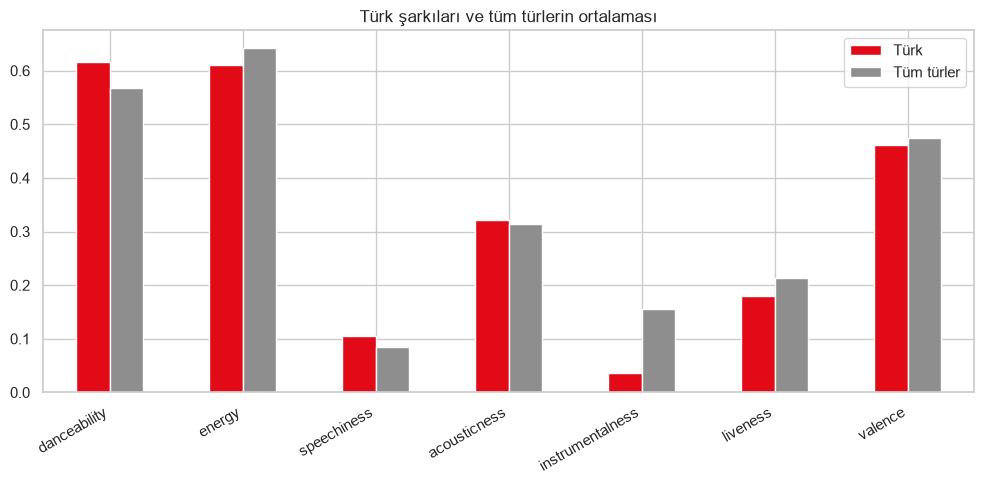

,Türk,Tüm türler,fark
instrumentalness,0.036,0.155,-0.119
energy,0.610,0.643,-0.033
liveness,0.181,0.213,-0.033
valence,0.462,0.475,-0.013
acousticness,0.322,0.314,0.008
speechiness,0.105,0.085,0.020
danceability,0.616,0.568,0.049


In [18]:
ozellikler_01 = ["danceability", "energy", "speechiness", "acousticness",
                 "instrumentalness", "liveness", "valence"]  # 0-1 aralığındakiler

karsilastirma = pd.DataFrame({
    "Türk": df.loc[df["track_genre"] == "turkish", ozellikler_01].mean(),
    "Tüm türler": df[ozellikler_01].mean(),
})
karsilastirma["fark"] = karsilastirma["Türk"] - karsilastirma["Tüm türler"]

fig, eksen = plt.subplots(figsize=(10, 5))
karsilastirma[["Türk", "Tüm türler"]].plot.bar(ax=eksen, color=["#E30A17", "#8E8E8E"])
eksen.set_title("Türk şarkıları ve tüm türlerin ortalaması")
eksen.set_xticklabels(eksen.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIGURLER / "01_turk_vs_dunya.png", dpi=120)
plt.show()

karsilastirma.round(3).sort_values("fark")

In [19]:
# Veri setindeki en popüler Türk şarkıları
(df[df["track_genre"] == "turkish"]
 .sort_values("popularity", ascending=False)
 [["track_name", "artists", "popularity", "valence", "energy"]]
 .head(10))

,track_name,artists,popularity,valence,energy
112041,Seni Dert Etmeler,Madrigal,77,0.8350,0.608
111791,M.,Anıl Emre Daldal,75,0.4440,0.366
111641,Arıyorum,EDIS,72,0.3810,0.730
111400,Rockstar,Ilkay Sencan;Dynoro,70,0.1850,0.826
112042,Nerdesin,Ezhel,69,0.8100,0.696
111842,Martılar,EDIS,69,0.8980,0.611
111407,Astronaut In The Ocean,Arem Ozguc;Arman Aydin;Jordan Rys,68,0.5440,0.867
111392,La Câlin,Serhat Durmus,67,0.0673,0.439
111542,Ay Tenli Kadın,Ufuk Beydemir,67,0.3350,0.541
111891,Şımarık,Tarkan,66,0.8260,0.818


## 8. Özet

**Veri kalitesi**
- 114.000 satırın 113.386'sı temizlikten geçti. Tekil şarkı sayısı **89.578**.
- Şarkıların ~%18'i birden fazla türde geçiyor. Klasik rock şarkıları 8–9 türe kadar çıkıyor. Şarkı düzeyindeki analizlerde tekrarlar atılacak, aksi hâlde model başarısı şişer.
- Şarkıların **%10.5'inin popülerliği tam 0**. Popülerlik tahmininde bunlara özel dikkat gerekecek.

**İlk bulgular**
- **Ses özellikleri popülerliği neredeyse hiç açıklamıyor:** En güçlü korelasyon bile ±0.13 düzeyinde (`instrumentalness`). Popülerlik tahmininin zor olacağının ilk işareti.
- **Türler arasında belirgin farklar var:** En mutlu türler salsa ve forró, en hüzünlüleri sleep ve iranian. Bu, kümelemenin anlamlı gruplar bulabileceğini gösteriyor.
- **İsimler yanıltabiliyor:** `happy` türü en enerjik 5 tür arasında, `sad` türü ise en popüler 5 tür arasında.
- **Türk müziği ilk bakışta:** Ortalamaya göre daha dans edilebilir ve daha "konuşkan" (rap etkisi). Sözsüz parça neredeyse yok (instrumentalness 0.04, genel ortalama 0.16). Mutluluk seviyesi ise dünya ortalamasıyla hemen hemen aynı.

**Sonraki adım:** `02_kumeleme.ipynb` — şarkıları ses özelliklerine göre doğal gruplara ayırmak.